# The app end to end: from a snake photo to a verdict and first aid

This notebook runs the whole SerpentGuard app on a laptop CPU. A photo goes through five steps: fix
its exposure, find the snake with the detector and crop to it, name the species with our final
model, turn the model's outputs into a verdict, and look up the WHO first-aid passages and a species
card for that verdict. We run the app on 100 validation photos and 5 short clips and check its
answers against the training run, annotate one clip the way the screen shows it, compare three ways
of finding first-aid passages for a typed question, and look at how big and how fast the app is once
exported for a phone.

It needs the final trained model, its verdict thresholds, the fine-tuned snake detector, a local
sample of validation photos and the WHO South-East Asia snakebite guideline (2016) as a PDF. The
guideline's text never enters the repo: we keep page numbers, character offsets and hashes, and cut
each passage from the PDF when the notebook runs. It writes the retrieval table
`results/m3/q1/retrieval.csv` and the demo clip's insights (passage ids and pages only). It runs on
the laptop's CPU in about two minutes.

In [1]:
# libraries: pip install -r ../requirements-m3.txt (this venv already has them)
import hashlib, json, os, pickle, shutil, subprocess, sys, tempfile, time, warnings
from collections import Counter
from dataclasses import asdict
from pathlib import Path

os.environ.update(YOLO_VERBOSE="False", YOLO_OFFLINE="1")  # quiet, and no network from ultralytics
warnings.filterwarnings("ignore")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import torch
from onnxruntime.quantization.shape_inference import quant_pre_process
from onnxruntime.transformers.float16 import convert_float_to_float16
from PIL import Image
from rank_bm25 import BM25Okapi
from scipy.stats import binomtest
from tokenizers import Tokenizer
from ultralytics import YOLO

sys.path.insert(0, "../src")
from serpentguard import decide, video
from serpentguard.data import AUGMENT, apply_mode, fix_exposure, load_rgb
from serpentguard.models import build_model

ort.disable_telemetry_events()  # the app runs offline

Where the inputs live. Everything that is not in the repo sits beside it, in `kaggle/`, `refs/` and
`outputs/`.

In [2]:
KAGGLE = Path("../../kaggle")
RUN_DIR = KAGGLE / "m3_runs/stageC/final_candidates/top1_s1/H1_top1_s1"  # the final model
DECISION_FILE = Path("../results/m3/final/H1_top1_s1/decision_metrics.json")  # its thresholds
DETECTOR = KAGGLE / "m3_runs/frontends/weights/frontends/D1/yolo26n-ft/detector.pt"
SAMPLE_DIR = KAGGLE / "m3_runs/local_sample/out2/local_sample"  # manifest.csv, photos under data/
WHO_PDF = Path("../../refs/who_searo_2016.pdf")  # the guideline, never committed
MINILM_DIR = KAGGLE / "m3_runs/q1/models"  # the int8 sentence models, never committed
RESULTS = Path("../results/m3")
DEMO_OUT = Path("../../outputs/demo")  # the annotated video, never committed
DEMO_PHOTO = "val/bungarus_caeruleus/inaturalist_754593781.jpg"
N_PHOTOS, N_CLIPS, SEED = 100, 5, 42

## 1. The pipeline

First we load what the five steps need: the final model from its checkpoint (the best run of the
tuning search, saved as `H1_top1_s1`), its verdict thresholds, the class prototypes each photo is
compared with, and the detector.

In [3]:
checkpoint = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=True)
cfg = checkpoint["config"]
model = build_model(cfg)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
decision = json.loads(DECISION_FILE.read_text())
assert decision["scorer"] == "head"  # fitted on the species head, which the app reads
thresholds = decide.Thresholds(**decision["thresholds"])
tau_snake = decision["no_snake"]["tau_snake"]  # a weaker detector box means "no snake found"
with np.load(RUN_DIR / "prototypes.npz") as saved:
    prototypes = saved[decision["prototype_set"]]
tables = decide.repo_tables()  # per species: dangerous or not, WHO category, genus and family
detector = YOLO(DETECTOR)
snake_class = [i for i, name in detector.names.items() if name.lower() == "snake"]
print(f"model {cfg['run_id']}: {cfg['encoder']} encoder, {cfg['input_size']} px input")
print(f"detector confidence needed for a snake: {tau_snake}")
print("thresholds:", {name: round(value, 3) for name, value in decision["thresholds"].items()})

model H1_top1_s1: mobilevit_s encoder, 320 px input
detector confidence needed for a snake: 0.102
thresholds: {'temperature': 1.909, 'temperature_who': 0.969, 'theta_d': 0.057, 'theta_who': inf, 'tau_unknown': 0.41, 'theta_conf': 0.361, 'theta_v': 0.5, 'theta_genus': 0.5}


The thresholds file must belong to this model. So we run the verdict rules on the model's own saved
validation outputs and compare the verdict counts with the ones the file records. The file's counts
also include photos its run flagged as showing no snake or a dark or blurry image, flags it did not
save per photo, so the two may differ by up to that many photos.

In [4]:
KEYS = ["embedding", "species_logits", "who_logits", "genus_logits", "family_logits"]
with np.load(RUN_DIR / "val_outputs.npz") as saved:
    val_outputs, val_paths = {key: saved[key] for key in KEYS}, saved["paths"].astype(str)
labels = decide.decide(val_outputs, thresholds, prototypes, tables).label
counts = {v: int((labels == v).sum()) for v in ("dangerous", "not_listed", "unknown")}
in_file = decision["verdicts"]["val"]
slack = decision["no_snake"]["val"] + decision["poor_image"]["flagged"]["val"]
assert len(labels) == in_file["total"] and all(abs(counts[v] - in_file[v]) <= slack for v in counts)
print("validation verdicts from the saved outputs:", counts)
print("validation verdicts in the thresholds file:", {v: in_file[v] for v in counts})
print(f"within the {slack} photos the file flagged: the file belongs to this model")

validation verdicts from the saved outputs: {'dangerous': 7891, 'not_listed': 7758, 'unknown': 1502}
validation verdicts in the thresholds file: {'dangerous': 7778, 'not_listed': 7737, 'unknown': 1636}
within the 2962 photos the file flagged: the file belongs to this model


The first-aid passages come from the guideline PDF. The repo keeps only an index: each passage's
page, its character offsets in that page's text, and a hash of the text. We cut every passage from
the PDF and check its hash, so a different printing of the PDF fails loudly instead of quoting the
wrong words. The 184 species cards are in our own words and live in the repo. We never print a
passage's text, only its id and page.

In [5]:
def page_text(page):
    """One PDF page as `pdftotext -raw` reads it; the index's offsets point into this text."""
    command = ["pdftotext", "-raw", "-enc", "UTF-8", "-eol", "unix",
               "-f", str(page), "-l", str(page), WHO_PDF, "-"]
    return subprocess.run(command, capture_output=True, text=True, check=True).stdout


index = pd.read_csv("../data/m3/kb/who_passages.csv", dtype={"sha256": str})
pages = {page: page_text(page) for page in index["page"].unique()}
who = []
for row in index.itertuples():
    text = pages[row.page][row.start:row.end]
    assert hashlib.sha256(text.encode()).hexdigest()[:16] == row.sha256, f"{row.id} fails its hash"
    who.append({"id": row.id, "text": text, "source": "WHO SEARO 2016", "page": int(row.page)})
card_table = pd.read_csv("../data/m3/kb/species_cards.csv", keep_default_na=False)
cards = [{"id": c.id, "text": c.text, "source": "SerpentGuard species card", "page": None,
          "species": c.species} for c in card_table.itertuples()]
kb = who + cards
lengths = pd.Series([len(p["text"]) for p in who])
print(f"{len(who)} guideline passages from {len(pages)} PDF pages, every one matching its hash; "
      f"{len(cards)} species cards")
print(f"characters per passage: median {lengths.median():.0f}, "
      f"min {lengths.min()}, max {lengths.max()}")
index.groupby("topic").agg(passages=("id", "size"), pdf_pages=("page", "nunique")).T

168 guideline passages from 45 PDF pages, every one matching its hash; 184 species cards
characters per passage: median 306, min 61, max 892


topic,aftercare,eye,first_aid,identification,prevention,snakes,symptoms,transport
passages,10,9,28,1,22,63,33,2
pdf_pages,4,2,6,1,4,22,8,1


The screen picks its passages with a fixed lookup by verdict (called R0 in section 4). "Dangerous"
shows six first-aid passages, then the card of the likeliest dangerous species in the top 3. "Not on
the WHO list" shows a note, the top species' card, then first aid. "We don't know" shows a note with
the reason, then first aid. So first aid is on every screen, and a dangerous verdict never shows a
card that says "not listed".

In [6]:
FIRST_AID = ["who-110-01", "who-119-04", "who-118-04", "who-119-03", "who-120-02", "who-120-05"]
REASONS = {"no_snake": "no snake found", "unclear_between_species": "unclear between species",
           "unfamiliar": "unlike any species we know", "poor_image": "the photo is dark or blurry",
           "no_majority": "the frames do not agree"}
by_id = {p["id"]: p for p in kb}
card_of = {p["species"]: p for p in cards}
medical = pd.read_csv("../data/m3/medical_importance.csv", keep_default_na=False)
dangerous_species = set(medical.loc[medical["dangerous"].astype(str) == "True", "species"])


def note(note_id, text):
    return {"id": note_id, "text": text, "source": "SerpentGuard", "page": None}


def lookup(label, species=(), reasons=()):
    """The passages for a verdict: first aid always, a species card where one fits, and a note."""
    first_aid = [by_id[pid] for pid in FIRST_AID]
    if label == "dangerous":
        name = next((s for s in species if s in dangerous_species), None)
        return first_aid + ([card_of[name]] if name in card_of else [])
    if label == "not_listed":
        card = [card_of[species[0]]] if species and species[0] in card_of else []
        return [note("note-not-listed", "not on the WHO list, still keep away")] + card + first_aid
    why = ", ".join(REASONS[r] for r in reasons if r in REASONS) or "no reason recorded"
    text = f"we don't know: {why}; give first aid as if the snake were dangerous"
    return [note("note-unknown", text)] + first_aid

Now the five steps as one function. A photo can be a file or a frame of a video. The detector looks
at the whole photo and returns its best snake box; below `tau_snake` the screen says "no snake
found" and the model is skipped. Otherwise we crop to the box with a small margin, letterbox the
crop to 320 px and run the model. The verdict rules live in `serpentguard.decide`: they read the
temperature-scaled species probabilities, the WHO, genus and family heads, and how close the photo
is to the nearest class prototype. Each step is timed.

In [7]:
def find_snake(rgb):
    """The detector's most confident snake box (x1, y1, x2, y2) and its confidence."""
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    found = detector.predict(bgr, conf=0.05, classes=snake_class, rect=False, verbose=False)[0]
    if not len(found.boxes):  # rect=False above pads every photo to a square, as in training
        return None, None
    best = int(found.boxes.conf.argmax())
    return found.boxes.xyxy[best].tolist(), float(found.boxes.conf[best])

In [8]:
def run_photo(image):
    """A photo (file or RGB frame) through the five steps: the screen, the box and ms per step."""
    times = [time.perf_counter()]
    rgb = load_rgb(image) if isinstance(image, (str, Path)) else fix_exposure(image)
    times.append(time.perf_counter())
    box, conf = find_snake(rgb)
    snake = conf is not None and conf >= tau_snake
    times.append(time.perf_counter())
    outputs = None
    if snake:
        crop = apply_mode(rgb, None, "box_crop", box, cfg["input_size"])[0]
        with torch.inference_mode():
            out = model(AUGMENT["eval"](image=crop)["image"][None])
        outputs = {key: out[key].float().numpy() for key in KEYS}
    times.append(time.perf_counter())
    shown = asdict(decide.verdict(outputs, thresholds, prototypes, tables, snake_found=snake))
    times.append(time.perf_counter())
    shown["passages"] = lookup(shown["label"], [name for name, _ in shown["top3"]], shown["reason"])
    times.append(time.perf_counter())
    ms = dict(zip(["preprocess", "detector", "model", "verdict", "passages"], np.diff(times) * 1e3))
    return {**shown, "box": box, "box_conf": conf, "snake_found": snake, "ms": ms}

Here it is on one photo: a common krait from the validation photos, a WHO Category 1 species. The
screen shows the verdict, the top three species with their probabilities, and the passages with
their PDF pages. This first call also carries one-off start-up costs, so its times are high.

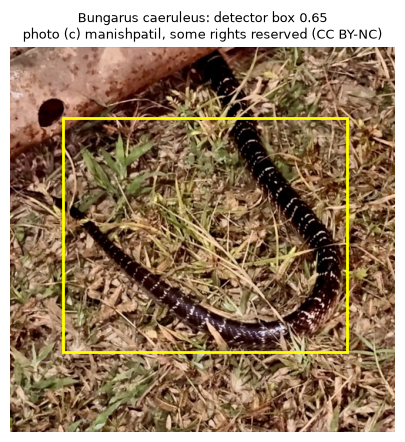

verdict: dangerous: WHO Category 1
top 3: Bungarus caeruleus 97%, Bungarus bungaroides 1%, Bungarus walli 1%
passages: who-110-01 (PDF p. 110), who-119-04 (PDF p. 119), who-118-04 (PDF p. 118), who-119-03 (PDF p. 119), who-120-02 (PDF p. 120), who-120-05 (PDF p. 120), card-029
ms per step: {'preprocess': 3.1, 'detector': 53.1, 'model': 73.2, 'verdict': 0.6, 'passages': 0.0}


In [9]:
manifest = pd.read_csv(SAMPLE_DIR / "manifest.csv", dtype=str, keep_default_na=False)
demo_row = manifest.set_index("path").loc[DEMO_PHOTO]
demo_file = SAMPLE_DIR / "data" / DEMO_PHOTO
screen = run_photo(demo_file)

plt.figure(figsize=(5, 5))
plt.imshow(load_rgb(demo_file))
if screen["box"]:
    x1, y1, x2, y2 = screen["box"]
    plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", lw=2))
plt.title(f"{demo_row['species']}: detector box {screen['box_conf']:.2f}\n"
          f"photo {demo_row['attribution']}", fontsize=9)
plt.axis("off")
plt.show()
print("verdict:", screen["message"])
print("top 3:", ", ".join(f"{name} {prob:.0%}" for name, prob in screen["top3"]))
print("passages:", ", ".join(f"{p['id']} (PDF p. {p['page']})" if p["page"] else p["id"]
                             for p in screen["passages"]))
print("ms per step:", {step: round(float(ms), 1) for step, ms in screen["ms"].items()})

## 2. 100 photos and 5 clips

Now the same pipeline on 100 validation photos, one from each of 100 classes, the classes taken in a
seeded random order. Each photo has an expected verdict: "dangerous" for a species on our danger
table (WHO-listed, a viper or an elapid, or a keelback), "not on the WHO list" otherwise. "We don't
know" is never expected, but on a species outside the table it is the cautious answer, not a
failure. A missed danger is a danger-table snake not called dangerous; a false alarm is any other
snake called dangerous.

In [10]:
def failure(expected, verdict):
    if expected == "dangerous" and verdict != "dangerous":
        return "missed danger"
    return "false alarm" if expected == "not_listed" and verdict == "dangerous" else ""


classes = pd.read_csv("../data/classes.csv")
val = manifest[manifest["use"].eq("val") & manifest["split"].eq("val")]
val = val.assign(class_id=val["species"].map(dict(zip(classes["species"], classes["class_id"]))))
assert val["class_id"].notna().all(), "every validation species must be in classes.csv"
photos = video.round_robin(val, N_PHOTOS, SEED).astype({"class_id": int})
photos["expected"] = [decide.expected_verdict(c, tables) for c in photos["class_id"]]
photos["who_listed"] = tables.who[photos["class_id"]] > 0
danger = (photos["expected"] == "dangerous").sum()
print(f"{len(photos)} photos from {photos['species'].nunique()} classes")
print(f"{danger} of a danger-table species ({photos['who_listed'].sum()} WHO-listed), "
      f"{len(photos) - danger} not")
print("licences:", photos["license"].value_counts().to_dict())

100 photos from 100 classes
26 of a danger-table species (12 WHO-listed), 74 not
licences: {'cc-by-nc': 80, 'cc-by': 14, 'cc-by-nc-sa': 5, 'cc-by-sa': 1}


We run all 100, after one untimed call. The table counts each expected verdict against the verdict
the screen showed.

In [11]:
run_photo(SAMPLE_DIR / "data" / photos["path"].iloc[0])
started = time.time()
results = [run_photo(SAMPLE_DIR / "data" / path) for path in photos["path"]]
print(f"{len(results)} photos in {time.time() - started:.1f} s")
photos["verdict"] = [r["label"] for r in results]
photos["top1"] = [r["top3"][0][0] if r["top3"] else None for r in results]
photos["failure"] = [failure(e, v) for e, v in zip(photos["expected"], photos["verdict"])]
pd.crosstab(photos["expected"], photos["verdict"], margins=True)

100 photos in 7.9 s


verdict,dangerous,not_listed,unknown,All
expected,,,,
dangerous,25,0,1,26
not_listed,21,40,13,74
All,46,40,14,100


The details behind the table. The times show where each photo's time goes on this laptop; section 5
measures the speed of the files the phone would run.

In [12]:
ms = pd.DataFrame([r["ms"] for r in results])
print("median ms per step:", ms.median().round(2).to_dict())
print(f"median ms per photo: {ms.sum(axis=1).median():.1f}")
print("failures:", photos["failure"].value_counts().drop("", errors="ignore").to_dict())
unknown = Counter(reason for r in results if r["label"] == "unknown" for reason in r["reason"])
print("reasons for we don't know:", dict(unknown))
listed = photos[photos["who_listed"]]
called = (listed["verdict"] == "dangerous").sum()
print(f"WHO-listed photos called dangerous: {called} of {len(listed)}")
for row in photos[photos["failure"] == "missed danger"].itertuples():
    print(f"missed danger: {row.species} called {row.verdict} (top 1: {row.top1})")
alarms = (photos["failure"] == "false alarm").sum() / (photos["expected"] == "not_listed").sum()
whole = decision["verdict_metrics"]["false_alarm_outside_table"]
print(f"false alarms: {alarms:.2f} of the photos outside the table; {whole:.2f} on all validation")
has_card = [any(p["id"].startswith("card") for p in r["passages"]) for r in results]
no_card = sum(r["label"] == "dangerous" and not card for r, card in zip(results, has_card))
print(f"dangerous screens with no card (no top-3 species on the danger table): {no_card}")
print(f"photos with no snake found: {sum(not r['snake_found'] for r in results)}")

median ms per step: {'preprocess': 3.33, 'detector': 11.5, 'model': 63.23, 'verdict': 0.38, 'passages': 0.01}
median ms per photo: 78.5
failures: {'false alarm': 21, 'missed danger': 1}
reasons for we don't know: {'unclear_between_species': 14, 'unfamiliar': 1}
WHO-listed photos called dangerous: 12 of 12
missed danger: Ovophis monticola called unknown (top 1: Boiga multomaculata)
false alarms: 0.28 of the photos outside the table; 0.30 on all validation
dangerous screens with no card (no top-3 species on the danger table): 5
photos with no snake found: 0


### Does it agree with the training run?

The training run saved the model's outputs for every validation photo (on Kaggle's GPU, in half
precision). The same verdict rules on those saved outputs should give the verdicts and top-1 species
our CPU pipeline gave from the photo files. A few may differ, since the GPU run read each photo in
its own way. As a control we pair each photo with the next photo's saved outputs: agreement must
then fall to what two unrelated photos share.

In [13]:
row_of = {path: i for i, path in enumerate(val_paths)}
rows = [row_of[path] for path in photos["path"]]  # every sample photo is a validation photo
snake = np.array([r["snake_found"] for r in results])
saved_outputs = {key: value[rows] for key, value in val_outputs.items()}
from_saved = decide.decide(saved_outputs, thresholds, prototypes, tables, snake_found=snake)
saved_top1 = tables.species[from_saved.top1][snake]
our_top1 = photos["top1"].to_numpy()[snake]
agreement = pd.DataFrame({
    "verdict": [np.mean(from_saved.label == photos["verdict"]),
                np.mean(np.roll(from_saved.label, 1) == photos["verdict"])],
    "top-1 species": [np.mean(saved_top1 == our_top1),
                      np.mean(np.roll(saved_top1, 1) == our_top1)]},
    index=["same photo", "control: the next photo's outputs"])
our_prob = np.array([r["top3"][0][1] for r in results if r["snake_found"]])
gap = np.abs(from_saved.top1_prob[snake] - our_prob).max()
print(f"{len(rows)} photos matched, {snake.sum()} with a snake found; "
      f"largest gap in top-1 probability {gap:.3f}")
agreement.round(2)

100 photos matched, 100 with a snake found; largest gap in top-1 probability 0.187


,verdict,top-1 species
same photo,0.98,0.98
control: the next photo's outputs,0.37,0.01


Now 5 clips. Each is 10 seconds at 15 frames a second, made from one of the first five photos by the
clip recipe from milestone 1: camera pan, zoom and shake, motion blur, low light, noise, JPEG
compression, and leaves over the middle of the frame. The app reads at most 10 frames a second,
always the newest, and the screen changes only when 4 of the last 6 frames agree; until then it says
"we don't know". Flips and the time to a stable label (one that stays on screen for 1 second) count
that placeholder too.

In [14]:
NO_MAJORITY = {"label": "unknown", "message": "we don't know: the frames do not agree", "top3": (),
               "reason": ("no_majority",), "note": "", "genus_fallback": None}


def run_clip(frames, fps=15):
    """The frames the 10-a-second cap lets through, each run as a photo, then the 4-of-6 vote."""
    kept, shown_at = video.schedule(len(frames), fps, 0.1)
    own = [run_photo(frames[i]) for i in kept]
    voted = video.vote_k_of_n([r["label"] for r in own])
    newest, screens = {}, []
    for r, label in zip(own, voted):
        newest[r["label"]] = r
        screens.append(newest[label] if label else NO_MAJORITY)
    stable = video.video_metrics([s["label"] for s in screens], None, shown_at, len(frames) / fps)
    final = screens[-1]
    return {"kept": kept, "own": own, "screens": screens, "final": final["label"],
            "majority": voted[-1] is not None, "flips": stable["flips"],
            "raw_flips": sum(a["label"] != b["label"] for a, b in zip(own, own[1:])),
            "time_to_stable": stable["time_to_stable"], "final_stable": stable["final_stable"],
            "first_majority_at": next((float(t) for t, v in zip(shown_at, voted) if v), None),
            "per_frame": dict(Counter(r["label"] for r in own)),
            "passages": lookup(final["label"], [n for n, _ in final["top3"]], final["reason"])}

In [15]:
clips = []
started = time.time()
for i, photo in enumerate(photos.head(N_CLIPS).itertuples()):
    with Image.open(SAMPLE_DIR / "data" / photo.path) as image:  # as stored: the scene filmed
        frames = video.synthesize_clip(np.asarray(image.convert("RGB")), seed=SEED + i).frames
    clip = run_clip(frames)
    clips.append({"species": photo.species, "expected": photo.expected, "final": clip["final"],
                  "failure": failure(photo.expected, clip["final"]),
                  "frames read": len(clip["kept"]), "flips": clip["flips"],
                  "time to stable (s)": clip["time_to_stable"],
                  "first majority (s)": clip["first_majority_at"], "majority": clip["majority"],
                  "per-frame verdicts": clip["per_frame"]})
print(f"{len(clips)} clips of {len(frames)} frames in {time.time() - started:.1f} s")
pd.DataFrame(clips)

5 clips of 150 frames in 42.6 s


,species,expected,final,failure,frames read,flips,time to stable (s),first majority (s),majority,per-frame verdicts
0,Boiga siamensis,not_listed,dangerous,false alarm,101,1,0.4,0.4,True,{'dangerous': 101}
1,Oligodon cinereus,not_listed,dangerous,false alarm,101,13,0.1,0.9,True,"{'dangerous': 55, 'not_listed': 5, 'unknown': 41}"
2,Sibynophis subpunctatus,not_listed,unknown,,101,14,0.8,0.6,False,"{'dangerous': 40, 'unknown': 30, 'not_listed':..."
3,Calliophis bibroni,dangerous,dangerous,,101,1,0.4,0.4,True,{'dangerous': 101}
4,Python molurus,not_listed,dangerous,false alarm,101,1,0.4,0.4,True,"{'dangerous': 100, 'not_listed': 1}"


## 3. Demo: one clip as the app shows it

We film the krait photo from section 1 with the same clip recipe and draw the screen on every frame:
the verdict banner in its colour, the top three species, and the detector's box. A frame the app
skipped shows the last frame it read. Here are three of its frames.

In [16]:
COLOURS = {"dangerous": (200, 30, 30), "not_listed": (215, 120, 0), "unknown": (85, 85, 105)}  # RGB
FONT = cv2.FONT_HERSHEY_SIMPLEX


def draw(frame, screen, own):
    """The frame with the screen's verdict banner and top 3, and this frame's detector box."""
    image = frame.copy()
    if own["box"] is not None:
        x1, y1, x2, y2 = (int(v) for v in own["box"])
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 230, 0), 2)
    image[:36] = COLOURS[screen["label"]]
    cv2.putText(image, screen["message"], (8, 25), FONT, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    top3 = screen["top3"] or own["top3"]
    image[36:46 + 24 * len(top3)] //= 3  # a dark band behind the top 3
    for rank, (name, prob) in enumerate(top3, 1):
        cv2.putText(image, f"{rank}. {name} {prob:.0%}", (8, 38 + 24 * rank), FONT, 0.55,
                    (255, 255, 255), 1, cv2.LINE_AA)
    return image

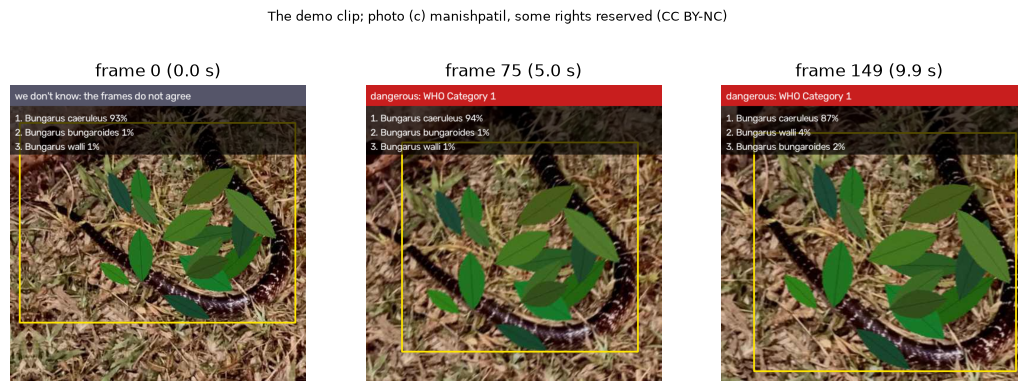

In [17]:
with Image.open(demo_file) as image:
    demo_clip = video.synthesize_clip(np.asarray(image.convert("RGB")), seed=SEED)
demo = run_clip(demo_clip.frames)
frame_count = len(demo_clip.frames)
read = np.searchsorted(demo["kept"], np.arange(frame_count), side="right") - 1  # last frame read
annotated = [draw(f, demo["screens"][j], demo["own"][j]) for f, j in zip(demo_clip.frames, read)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, frame_no in zip(axes, (0, 75, frame_count - 1)):
    ax.imshow(annotated[frame_no])
    ax.set_title(f"frame {frame_no} ({frame_no / 15:.1f} s)")
    ax.axis("off")
fig.suptitle(f"The demo clip; photo {demo_row['attribution']}", fontsize=9)
plt.show()

The whole annotated clip goes to `outputs/demo/` beside the repo, not into it, because it is made
from someone else's photo under that photo's licence.

In [18]:
DEMO_OUT.mkdir(parents=True, exist_ok=True)
height, width = (side - side % 2 for side in annotated[0].shape[:2])  # H.264 needs even sides
for codec in ("avc1", "mp4v"):  # H.264 where OpenCV has it, MPEG-4 Part 2 otherwise
    fourcc = cv2.VideoWriter_fourcc(*codec)
    writer = cv2.VideoWriter(str(DEMO_OUT / "annotated.mp4"), fourcc, 15, (width, height))
    if writer.isOpened():
        break
assert writer.isOpened(), "OpenCV cannot write an mp4 here"
for image in annotated:
    writer.write(cv2.cvtColor(image[:height, :width], cv2.COLOR_RGB2BGR))
writer.release()
print(f"wrote outputs/demo/annotated.mp4: {frame_count} frames at 15 a second, {width} x {height}, "
      f"codec {codec}")

wrote outputs/demo/annotated.mp4: 150 frames at 15 a second, 500 x 500, codec avc1


The insights file records what the clip showed: the final verdict, when it became stable, how often
the verdict flipped frame by frame and on screen, the species most often on top, and the passages by
id and page. It never holds the guideline's words, so it can be committed.

In [19]:
final = demo["screens"][-1]
top1 = Counter(r["top3"][0][0] for r in demo["own"] if r["top3"])
frame_ms = pd.DataFrame([r["ms"] for r in demo["own"]])
photo_info = {k: demo_row[k] for k in ("species", "license", "attribution", "url")}
thresholds_json = {name: value if np.isfinite(value) else "inf"  # JSON has no infinity
                   for name, value in decision["thresholds"].items()}
insights = {
    "input": {"photo": {"path": DEMO_PHOTO, **photo_info}, "clip_seed": SEED, "fps": 15,
              "frames": frame_count},
    "model": {"run_id": cfg["run_id"], "encoder": cfg["encoder"], "input_size": cfg["input_size"],
              "detector": DETECTOR.parent.name, "tau_snake": tau_snake},
    "decision": {"file": DECISION_FILE.name, "smoothing": "vote_4_of_6",
                 "thresholds": thresholds_json},
    "final": {"verdict": final["label"], "message": final["message"], "reason": final["reason"],
              "note": final["note"], "top3": final["top3"],
              "genus_fallback": final["genus_fallback"], "majority": demo["majority"],
              "final_stable": demo["final_stable"]},
    "timing": {"time_to_first_stable_s": demo["time_to_stable"],
               "first_majority_at_s": demo["first_majority_at"]},
    "flips": {"raw": demo["raw_flips"], "smoothed": demo["flips"], "raw_counts": demo["per_frame"]},
    "species_top1": [{"species": name, "share": round(n / len(demo["own"]), 4), "frames": n}
                     for name, n in top1.most_common(3)],
    "passages": [{"id": p["id"], "source": p["source"], "page": p["page"]}
                 for p in demo["passages"]],
    "speed": {"frames_read": len(demo["kept"]),
              "mean_frame_ms": round(frame_ms.sum(axis=1).mean(), 3),
              "mean_ms": frame_ms.mean().round(3).to_dict()}}
species = demo_row["species"].lower().replace(" ", "_")
(RESULTS / "demo" / f"final_{species}_insights.json").write_text(json.dumps(insights, indent=2))
print(f"{final['message']}; first stable at {demo['time_to_stable']} s; "
      f"flips: {demo['raw_flips']} frame by frame, {demo['flips']} on screen")
mean_ms = insights["speed"]["mean_frame_ms"]
print(f"{len(demo['kept'])} of {frame_count} frames read, {mean_ms:.1f} ms each")
print("species most often on top:", [(s["species"], s["share"]) for s in insights["species_top1"]])
print("passages:", [p["id"] for p in demo["passages"]])

dangerous: WHO Category 1; first stable at 0.4 s; flips: 0 frame by frame, 1 on screen
101 of 150 frames read, 77.8 ms each
species most often on top: [('Bungarus caeruleus', 1.0)]
passages: ['who-110-01', 'who-119-04', 'who-118-04', 'who-119-03', 'who-120-02', 'who-120-05', 'card-029']


## 4. Finding first-aid passages for a typed question

Section 1 used a fixed lookup by verdict. A person may also type a question, such as "how do I keep
the arm still?". We compare three ways to find the right passages, all small enough for a phone: the
fixed lookup (saved as R0), BM25 keyword ranking from the `rank_bm25` library (R1), and two small
sentence-embedding models in int8, MiniLM-L6 (R2-L6) and MiniLM-L3 (R2-L3). Nothing is generated:
the app only shows passages word for word, with their page.

BM25 scores a passage by the question's words it contains, rare words counting more. Words are
lower-cased, common words dropped and a plural "s" cut off; the stopword list is the one every
reported number used.

In [20]:
STOPWORDS = set("""
a about above after again against all am an and any are as at be because been before being below
between both but by can could did do does doing down during each few for from further had has
have having he her here hers him his how i if in into is it its itself just me more most my no
nor not now of off on once only or other our ours out over own same she should so some such than
that the their theirs them then there these they this those through to too under until up very
was we were what when where which while who whom why will with would you your yours im ive dont
didnt doesnt isnt cant got get gets also okay ok please yes one ones around along across onto
upon toward towards within without
""".split())


def tokenize(text):
    """Lower-case words minus stopwords, with a plural "s" cut from words over 4 letters."""
    text = text.replace("'", "").replace("’", "")
    words = "".join(c.lower() if c.isalnum() else " " for c in text).split()
    return [w[:-1] if len(w) > 4 and w.endswith("s") and not w.endswith("ss") else w
            for w in words if w not in STOPWORDS]


bm25 = BM25Okapi([tokenize(p["text"]) for p in kb])  # k1 = 1.5 and b = 0.75, the library's defaults


def bm25_search(text, k):
    return [kb[i] for i in np.argsort(-bm25.get_scores(tokenize(text)), kind="stable")[:k]]


question = "how do I keep the bitten arm still"
print(question, "->", [p["id"] for p in bm25_search(question, 3)])

how do I keep the bitten arm still -> ['who-110-04', 'who-105-02', 'who-102-02']


A sentence model turns a text into a vector, and passages whose vectors point the same way as the
question's rank first. Each model runs as an int8 ONNX file on one CPU thread, one text at a time
(int8 scales each batch, so batch neighbours would change a vector).

In [21]:
INPUTS = ["input_ids", "attention_mask", "token_type_ids"]


def onnx_session(path, threads=1):
    options = ort.SessionOptions()
    options.intra_op_num_threads, options.inter_op_num_threads = threads, 1
    options.log_severity_level = 3  # errors only
    return ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


def load_tokenizer(folder):
    tokenizer = Tokenizer.from_file(str(folder / "tokenizer.json"))
    settings = json.loads((folder / "sentence_bert_config.json").read_text())
    tokenizer.enable_truncation(settings["max_seq_length"])
    tokenizer.no_padding()
    return tokenizer


def encode(session, tokenizer, text):
    """The text's unit vector: the mean of its token vectors."""
    tokens = tokenizer.encode(text)
    values = (tokens.ids, tokens.attention_mask, tokens.type_ids)
    feed = {name: np.array([v], dtype=np.int64) for name, v in zip(INPUTS, values)}
    hidden = session.run(None, {i.name: feed[i.name] for i in session.get_inputs()})[0][0]
    mask = np.array(tokens.attention_mask, dtype=np.float32)[:, None]
    pooled = (hidden * mask).sum(axis=0) / max(mask.sum(), 1e-9)
    return pooled / np.linalg.norm(pooled)

The first time on a machine, `export_minilm` downloads each model at a pinned version, exports it to
ONNX, quantises it to int8 and checks it stays within cosine 0.99 of the PyTorch model on three
check sentences; afterwards the saved files are reused.

In [22]:
MINILM = {"L6": ("sentence-transformers/all-MiniLM-L6-v2",
                 "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"),
          "L3": ("sentence-transformers/paraphrase-MiniLM-L3-v2",
                 "4ca70771034acceecb2e72475f72050fcdde4ddc")}
CHECKS = ["a snake bit my leg while I was walking home", "how do I keep the arm still",
          "the photo is too dark to see the head"]


class LastHidden(torch.nn.Module):
    """A Hugging Face encoder's token vectors: the one output the ONNX file needs."""

    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder

    def forward(self, input_ids, attention_mask, token_type_ids):
        return self.encoder(input_ids=input_ids, attention_mask=attention_mask,
                            token_type_ids=token_type_ids).last_hidden_state

In [23]:
def export_minilm(name):
    """Downloads the pinned model, exports it to ONNX, quantises it to int8, checks it on CHECKS."""
    from huggingface_hub import hf_hub_download
    from onnxruntime.quantization import QuantType, quantize_dynamic
    from transformers import AutoModel
    (repo, revision), out = MINILM[name], MINILM_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    for file in ("tokenizer.json", "sentence_bert_config.json"):
        shutil.copy(hf_hub_download(repo, file, revision=revision), out / file)
    hf = AutoModel.from_pretrained(repo, revision=revision, attn_implementation="eager")
    net, tokenizer = LastHidden(hf).eval(), load_tokenizer(out)
    tokens = [tokenizer.encode(text) for text in CHECKS]
    inputs = [tuple(torch.tensor([v]) for v in (t.ids, t.attention_mask, t.type_ids))
              for t in tokens]
    axes = {key: {0: "batch", 1: "tokens"} for key in [*INPUTS, "last_hidden_state"]}
    torch.onnx.export(net, inputs[0], str(out / "model_fp32.onnx"), input_names=INPUTS,
                      output_names=["last_hidden_state"], dynamic_axes=axes, opset_version=17,
                      dynamo=False)
    quantize_dynamic(str(out / "model_fp32.onnx"), str(out / "model_int8.onnx"),
                     weight_type=QuantType.QInt8, per_channel=True)
    with torch.no_grad():  # no padding, so the plain mean over tokens is the pooled vector
        reference = [net(*x)[0].mean(dim=0).numpy() for x in inputs]
    session = onnx_session(out / "model_int8.onnx")
    cosine = min(float(encode(session, tokenizer, text) @ (r / np.linalg.norm(r)))
                 for text, r in zip(CHECKS, reference))
    assert cosine >= 0.99, f"{name}: the int8 model drifts from PyTorch (cosine {cosine:.4f})"
    record = {"name": name, "repo": repo, "revision": revision,
              "parameters": sum(p.numel() for p in hf.parameters()),
              "fp32_mb": (out / "model_fp32.onnx").stat().st_size / 2 ** 20,
              "int8_mb": (out / "model_int8.onnx").stat().st_size / 2 ** 20,
              "min_cosine_to_pytorch": {"model_int8.onnx": cosine},
              "max_seq_length": tokenizer.truncation["max_length"]}
    (out / "model_fp32.onnx").unlink()  # only the int8 file ships
    (out / "export.json").write_text(json.dumps(record, indent=2))

We load both int8 models (exporting them if this machine has not yet), encode every passage and card
once, and show each model's export record.

In [24]:
minilm = {}
for name in MINILM:
    if not (MINILM_DIR / name / "model_int8.onnx").exists():
        export_minilm(name)
    session = onnx_session(MINILM_DIR / name / "model_int8.onnx")
    tokenizer = load_tokenizer(MINILM_DIR / name)
    minilm[name] = session, tokenizer, np.stack([encode(session, tokenizer, p["text"]) for p in kb])


def minilm_search(name, text, k):
    session, tokenizer, vectors = minilm[name]
    scores = vectors @ encode(session, tokenizer, text)
    return [kb[i] for i in np.argsort(-scores, kind="stable")[:k]]


exports = pd.DataFrame([json.loads((MINILM_DIR / n / "export.json").read_text()) for n in MINILM])
exports["int8 cosine to PyTorch"] = [c["model_int8.onnx"] for c in exports["min_cosine_to_pytorch"]]
export_columns = ["name", "repo", "parameters", "max_seq_length", "fp32_mb", "int8_mb",
                  "int8 cosine to PyTorch"]
exports[export_columns].round(4)

,name,repo,parameters,max_seq_length,fp32_mb,int8_mb,int8 cosine to PyTorch
0,L6,sentence-transformers/all-MiniLM-L6-v2,22713216,256,86.1798,21.8915,0.9972
1,L3,sentence-transformers/paraphrase-MiniLM-L3-v2,17389824,128,65.8292,16.6390,0.9985


The 60 test questions are drafts we wrote ourselves, 20 in each of three styles: asked from a
verdict screen ("verdict"), sharing a key word with the right passage ("keyword"), or sharing no
content word with it ("paraphrase"). Each lists its gold passages. Recall@k is the share of
questions with a gold passage in the top k; MRR uses the first gold passage in the top 10. We time
each question five times on one thread and keep the median.

In [25]:
questions = pd.read_csv("../data/m3/response_questions.csv", keep_default_na=False)
search = {
    "R0": lambda q, k: lookup(q.verdict, [q.species] if q.species else [], q.reason.split(";"))[:k],
    "R1": lambda q, k: bm25_search(q.question, k),
    "R2-L6": lambda q, k: minilm_search("L6", q.question, k),
    "R2-L3": lambda q, k: minilm_search("L3", q.question, k)}


def gold_ranks(name, repeats=5):
    """Each question's first gold rank in the top 10 (or None) and the mean ms per question."""
    search[name](questions.iloc[0], 10)  # warm-up
    ranks, seconds = [], []
    for q in questions.itertuples():
        spent = []
        for _ in range(repeats):
            start = time.perf_counter()
            found = search[name](q, 10)
            spent.append(time.perf_counter() - start)
        seconds.append(np.median(spent))
        gold = q.gold_ids.split(";")
        ranks.append(next((i for i, p in enumerate(found, 1) if p["id"] in gold), None))
    return ranks, 1000 * np.mean(seconds)

What each method adds to the phone. The lookup keeps the first-aid passages, the cards, its notes
and which card goes with which species; BM25 keeps every passage and its word index; a sentence
model keeps every passage, their vectors, the model and its tokenizer.

In [26]:
def mb(passages, extra_bytes=0):
    return (sum(len(p["text"].encode()) for p in passages) + extra_bytes) / 2 ** 20


card_ids = {species: p["id"] for species, p in card_of.items()}
lookup_table = json.dumps({"first_aid": FIRST_AID, "cards": card_ids})
notes = [lookup("not_listed")[0], lookup("unknown")[0]]
size = {"R0": mb([by_id[i] for i in FIRST_AID] + cards + notes,
                 len(("".join(REASONS.values()) + lookup_table).encode())),
        "R1": mb(kb, len(pickle.dumps(bm25)))}
for n, (_, _, vectors) in minilm.items():
    files = sum((MINILM_DIR / n / f).stat().st_size for f in ("model_int8.onnx", "tokenizer.json"))
    size[f"R2-{n}"] = mb(kb, files + vectors.nbytes)
print("MB on the phone:", {name: round(value, 3) for name, value in size.items()})

MB on the phone: {'R0': 0.039, 'R1': 0.214, 'R2-L6': 22.94, 'R2-L3': 17.687}


Now every method on every question. Before writing the table we check that this code ranks every
question exactly as the committed run did (`results/m3/q1/ranks.csv`), so the simplified code gives
the same answers.

In [27]:
rows, ranks = [], questions[["id", "style", "verdict", "topic"]].copy()
for name in search:
    found, ms_per_question = gold_ranks(name)
    ranks[name] = pd.array(found, dtype="Int64")
    for style in ["all", "keyword", "paraphrase", "verdict"]:
        r = pd.Series(found, dtype="float")[(questions["style"] == style) | (style == "all")]
        rows.append({"retriever": name, "style": style, "recall1": (r == 1).mean(),
                     "recall3": (r <= 3).mean(), "mrr": (1 / r).fillna(0).mean(), "n": len(r),
                     "ms": ms_per_question, "mb": size[name]})
committed = pd.read_csv(RESULTS / "q1/ranks.csv")[list(search)].fillna(0).astype(int)
ours = ranks[list(search)].fillna(0).astype(int)
assert ours.equals(committed), "the gold ranks differ from the committed run"
print(f"gold ranks identical to the committed run for all {len(questions)} questions")
retrieval = pd.DataFrame(rows)
retrieval.to_csv(RESULTS / "q1/retrieval.csv", index=False, float_format="%.4f")
overall = retrieval[retrieval["style"] == "all"].set_index("retriever")
by_style = retrieval.pivot(index="retriever", columns="style", values="recall3")
summary = overall[["recall1"]].join(by_style.add_prefix("recall@3 "))
summary.join(overall[["mrr", "ms", "mb"]]).loc[list(search)].round(3)

gold ranks identical to the committed run for all 60 questions


,recall1,recall@3 all,recall@3 keyword,recall@3 paraphrase,recall@3 verdict,mrr,ms,mb
retriever,,,,,,,,
R0,0.100,0.400,0.25,0.35,0.60,0.265,0.001,0.039
R1,0.417,0.467,0.95,0.05,0.40,0.455,0.185,0.214
R2-L6,0.400,0.683,0.80,0.60,0.65,0.573,1.777,22.940
R2-L3,0.333,0.533,0.70,0.45,0.45,0.462,0.943,17.687


Our rule was that a sentence model must clearly beat BM25 on recall@3 to earn its megabytes in the
30 MB package. Both answer the same 60 questions, so we count the questions only one of the pair
gets into its top 3 and apply an exact two-sided sign test to those.

In [28]:
hits = ranks[list(search)].le(3).fillna(False).astype(bool)
tests = []
for name in ["R0", "R2-L6", "R2-L3"]:
    for style in ["all", "keyword", "paraphrase", "verdict"]:
        rows_in = (ranks["style"] == style) | (style == "all")
        it, bm = hits.loc[rows_in, name], hits.loc[rows_in, "R1"]
        only_it, only_bm25 = int((it & ~bm).sum()), int((~it & bm).sum())
        p = binomtest(only_it, only_it + only_bm25).pvalue if only_it + only_bm25 else np.nan
        tests.append({"method": name, "style": style, "questions": int(rows_in.sum()),
                      "only this method": only_it, "only BM25": only_bm25, "sign test p": p})
missed = ranks.loc[~hits.any(axis=1), "id"].tolist()
print(f"{len(missed)} questions no method answers in its top 3: {missed}")
pd.DataFrame(tests).round(4)

3 questions no method answers in its top 3: ['P08', 'P09', 'P20']


,method,style,questions,only this method,only BM25,sign test p
0,R0,all,60,14,18,0.5966
1,R0,keyword,20,0,14,0.0001
2,R0,paraphrase,20,7,1,0.0703
3,R0,verdict,20,7,3,0.3438
4,R2-L6,all,60,20,7,0.0192
5,R2-L6,keyword,20,1,4,0.3750
6,R2-L6,paraphrase,20,11,0,0.0010
7,R2-L6,verdict,20,8,3,0.2266
8,R2-L3,all,60,13,9,0.5235
9,R2-L3,keyword,20,0,5,0.0625


## 5. Size and speed on a laptop

The phone app must fit in 30 MB and show a verdict at least 10 times a second. The tables below come
from the full export run of this step on the laptop (an Apple M4 Pro) on 6 November 2026: every
candidate model exported to ONNX in each precision, checked against its float32 export, and timed
100 times on one thread; we read its saved files rather than redo it. "int8" does all the arithmetic
in 8-bit integers, "int8 weights" stores the weights in 8 bits but computes in float, and "fp16"
stores everything in half precision. File sizes are in MB of 10^6 bytes; the models carry untrained
weights apart from the detector, since size and speed don't depend on the weights.

In [29]:
X1 = RESULTS / "x1_laptop"
quant = pd.read_csv(X1 / "quantization.csv")
quant["name"] = quant["model"] + " @" + quant["size"].astype(str)
chosen = quant[quant["chosen"]].set_index("name")  # the int8 variant picked for each model
by_variant = quant.pivot(index="name", columns="variant", values="variant_mb")
sizes = pd.DataFrame({"fp32": quant.groupby("name")["fp32_mb"].first(),
                      "int8": chosen["variant_mb"], "int8 weights": by_variant["int8_weights"],
                      "fp16": by_variant["fp16"]})
package = pd.read_csv(X1 / "package.csv")
shipped = package[(package["precision"] == "deployment") & (package["front_end"] != "none")]
final_row = shipped[(shipped["snakeid"] == "snakeid_" + cfg["encoder"])
                    & (shipped["front_end"] == "yolo26n-ft@320")].iloc[0]
names = {"total_mb": "MB", "total_mb_with_R1": "with BM25", "total_mb_with_R2-L6": "with MiniLM-L6"}
print("Model in fp16, detector in int8 weights, class prototypes; MB against the 30 MB budget:")
budget = shipped[["snakeid", "front_end", *names]].rename(columns=names).round(2)
print(budget.to_string(index=False))
print("\nEach file in MB:")
sizes.round(2)

Model in fp16, detector in int8 weights, class prototypes; MB against the 30 MB budget:
                       snakeid      front_end    MB  with BM25  with MiniLM-L6
snakeid_mobilenetv4_conv_small yolo26n-ft@320  5.85       6.06           28.79
snakeid_mobilenetv4_conv_small yolo26n-ft@640  5.98       6.19           28.92
       snakeid_efficientnet_b0 yolo26n-ft@320 11.51      11.73           34.45
       snakeid_efficientnet_b0 yolo26n-ft@640 11.64      11.85           34.58
           snakeid_mobilevit_s yolo26n-ft@320 13.30      13.51           36.24
           snakeid_mobilevit_s yolo26n-ft@640 13.42      13.64           36.36

Each file in MB:


,fp32,int8,int8 weights,fp16
name,,,,
snakeid_efficientnet_b0 @320,17.51,5.28,4.66,8.82
snakeid_mobilenetv4_conv_small @320,6.26,1.87,1.68,3.15
snakeid_mobilevit_s @320,20.75,6.01,5.53,10.60
yolo26n-ft @320,9.68,3.00,2.65,4.91
yolo26n-ft @640,9.81,3.07,2.77,4.97


And the speed: the whole app per photo, then each file on its own.

In [30]:
latency = pd.read_csv(X1 / "latency.csv")
latency["name"] = latency["model"] + " @" + latency["size"].astype(str)
one = latency[latency["threads"] == 1].set_index("name")
speeds = pd.DataFrame({
    "fp32": one.loc[one["precision"] == "fp32", "median_ms"],
    "int8": one.loc[one["variant"] == chosen["variant"].reindex(one.index), "median_ms"],
    "int8 weights": one.loc[one["variant"] == "int8_weights", "median_ms"],
    "fp16": one.loc[one["variant"] == "fp16", "median_ms"]})
names = {"pipeline_ms_1t": "ms", "pipeline_fps_1t": "photos a second",
         "meets_10fps_1t": "10 a second"}
print("The whole app per photo (model + detector) on one thread:")
pace = shipped[["snakeid", "front_end", *names]].rename(columns=names).round(1)
print(pace.to_string(index=False))
print("\nEach file, median ms per photo on one thread:")
speeds.round(1)

The whole app per photo (model + detector) on one thread:
                       snakeid      front_end    ms  photos a second  10 a second
snakeid_mobilenetv4_conv_small yolo26n-ft@320  17.3             57.9         True
snakeid_mobilenetv4_conv_small yolo26n-ft@640  36.0             27.8         True
       snakeid_efficientnet_b0 yolo26n-ft@320  41.3             24.2         True
       snakeid_efficientnet_b0 yolo26n-ft@640  60.0             16.7         True
           snakeid_mobilevit_s yolo26n-ft@320  84.9             11.8         True
           snakeid_mobilevit_s yolo26n-ft@640 103.6              9.7        False

Each file, median ms per photo on one thread:


,fp32,int8,int8 weights,fp16
name,,,,
snakeid_mobilenetv4_conv_small @320,7.6,3.9,7.6,7.4
snakeid_efficientnet_b0 @320,31.4,20.2,31.7,31.3
snakeid_mobilevit_s @320,50.9,55.3,58.9,75.0
yolo26n-ft @320,6.7,8.8,9.9,7.6
yolo26n-ft @640,25.8,36.2,28.6,29.5


Why not int8 everywhere, the smallest option? On untrained models int8 looked faithful (correlation
with float32 above 0.97 in the export run). On our trained model it collapses: training leaves
outliers that one 8-bit range per tensor rounds away (an activation peaking near 100 where most
values are under 1, and weights that differ up to 46-fold between channels). Here is the final model
on 300 validation photos in each precision, and the detector's boxes in each precision against its
float32 boxes.

In [31]:
accuracy = json.loads((X1 / f"accuracy_{cfg['run_id']}.json").read_text())
finding = pd.DataFrame([{"precision": variant, "top-1": scored["headline"]["quantised"]["top1"],
                         "keeps the fp32 top-1": scored["agreement"]["top1_agreement"],
                         "MB": accuracy["variant_mb"][variant]}
                        for variant, scored in accuracy["variants"].items()])
fp32_top1 = next(iter(accuracy["variants"].values()))["headline"]["fp32"]["top1"]
print(f"final model on {accuracy['photos']} validation photos: top-1 {fp32_top1:.3f} in float32")
boxes = quant[quant["name"] == "yolo26n-ft @320"].set_index("variant")["detection_agreement"]
print("detector at 320 px, share of photos keeping the fp32 box:", boxes.round(3).to_dict())
finding.round(3)

final model on 300 validation photos: top-1 0.363 in float32
detector at 320 px, share of photos keeping the fp32 box: {'static_qdq': 0.683, 'int8_weights': 0.99, 'fp16': 1.0}


,precision,top-1,keeps the fp32 top-1,MB
0,static_qdq_attention_fp32,0.050,0.093,6.083
1,dynamic,0.037,0.080,5.632
2,int8_weights,0.363,0.923,5.633
3,fp16,0.363,1.000,10.667


A quick check on this machine: we export the final model to fp16 ONNX and the detector with int8
weights, the two files the app would ship, and time each once (one thread, the median of 20 runs
after 10 warm-up runs). The `int8_weights` function stores each Conv, MatMul and Gemm weight as int8
with one scale per output channel; a DequantizeLinear node turns it back to float before use, so the
arithmetic stays in float.

In [32]:
def int8_weights(source, target):
    quant_pre_process(str(source), str(target))
    onnx_model = onnx.load(str(target))
    graph, done = onnx_model.graph, set()
    weights = {tensor.name: tensor for tensor in graph.initializer}
    for node in list(graph.node):
        weighted = node.op_type in ("Conv", "MatMul", "Gemm") and len(node.input) > 1
        name = node.input[1] if weighted else None
        tensor = weights.get(name)
        if (tensor is None or name in done or tensor.data_type != onnx.TensorProto.FLOAT
                or len(tensor.dims) < 2):
            continue
        weight = onnx.numpy_helper.to_array(tensor)
        flipped = node.op_type == "Gemm" and any(a.name == "transB" and a.i for a in node.attribute)
        axis = 0 if node.op_type == "Conv" or flipped else weight.ndim - 1  # the output channels
        scale = np.abs(weight).max(axis=tuple(i for i in range(weight.ndim) if i != axis)) / 127
        scale = np.where(scale > 0, scale, 1).astype(np.float32)
        shape = [-1 if i == axis else 1 for i in range(weight.ndim)]
        stored = np.clip(np.round(weight / scale.reshape(shape)), -127, 127).astype(np.int8)
        parts = [name + "_int8", name + "_scale", name + "_zero_point"]
        arrays = (stored, scale, np.zeros_like(scale, dtype=np.int8))
        graph.initializer.remove(tensor)
        graph.initializer.extend(onnx.numpy_helper.from_array(a, p) for a, p in zip(arrays, parts))
        graph.node.insert(0, onnx.helper.make_node("DequantizeLinear", parts, [name], axis=axis))
        done.add(name)
    onnx.save(onnx_model, str(target))

In [33]:
def median_ms(path, size=320, runs=20):
    """Median ms per photo on one thread, after 10 warm-up runs, on a random photo-sized input."""
    session = onnx_session(path, threads=1)
    image = np.random.default_rng(0).random((1, 3, size, size), dtype=np.float32)
    feed = {session.get_inputs()[0].name: image}
    for _ in range(10):
        session.run(None, feed)
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        session.run(None, feed)
        times.append(time.perf_counter() - start)
    return 1000 * np.median(times)


class Heads(torch.nn.Module):
    """Our model's five outputs as a tuple, the form ONNX export takes."""

    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, images):
        out = self.net(images)
        return tuple(out[key] for key in KEYS)

In [34]:
with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    sample = (torch.zeros(1, 3, 320, 320),)
    torch.onnx.export(Heads(model).eval(), sample, str(folder / "model.onnx"),
                      input_names=["images"], output_names=KEYS, opset_version=17, dynamo=False,
                      dynamic_axes={name: {0: "batch"} for name in ["images", *KEYS]})
    fp16 = convert_float_to_float16(onnx.load(str(folder / "model.onnx")), keep_io_types=True)
    onnx.save(fp16, str(folder / "model_fp16.onnx"))
    shutil.copy(DETECTOR, folder / "detector.pt")  # its ONNX file lands beside the weights
    exported = YOLO(folder / "detector.pt").export(format="onnx", imgsz=320, opset=17, half=False,
                                                   simplify=False, dynamic=False, verbose=False)
    int8_weights(exported, folder / "detector_int8_weights.onnx")
    files = {"model, fp16": folder / "model_fp16.onnx",
             "detector, int8 weights": folder / "detector_int8_weights.onnx"}
    timed = pd.DataFrame({"MB now": {n: f.stat().st_size / 1e6 for n, f in files.items()},
                          "ms now": {n: median_ms(f) for n, f in files.items()}})
model_row = next(r for r in accuracy["latency"] if r["variant"] == "fp16" and r["threads"] == 1)
detector_row = one[(one.index == "yolo26n-ft @320") & (one["variant"] == "int8_weights")].iloc[0]
timed["MB committed"] = [model_row["mb"], detector_row["mb"]]
timed["ms committed"] = [model_row["median_ms"], detector_row["median_ms"]]
now, before = timed["ms now"].sum(), timed["ms committed"].sum()
print(f"together: {now:.1f} ms per photo now ({1000 / now:.1f} a second), "
      f"{before:.1f} ms in the committed run")
timed.round(2)

together: 84.5 ms per photo now (11.8 a second), 85.0 ms in the committed run


,MB now,ms now,MB committed,ms committed
"model, fp16",10.64,75.00,10.67,75.06
"detector, int8 weights",2.63,9.52,2.65,9.92


## Results at a glance

In [35]:
clip_finals = Counter(c["final"] for c in clips)
failures = photos["failure"].value_counts()
int8_kept = [v["agreement"]["top1_agreement"] for k, v in accuracy["variants"].items()
             if k not in ("int8_weights", "fp16")]
pd.DataFrame({"value": {
    "verdicts agreeing with the training run": f"{agreement.iloc[0, 0]:.0%} "
                                               f"(control {agreement.iloc[1, 0]:.0%})",
    "WHO-listed photos called dangerous": f"{called} of {len(listed)}",
    "missed dangers, false alarms (100 photos)": f"{failures.get('missed danger', 0)}, "
                                                 f"{failures.get('false alarm', 0)}",
    "clips ending dangerous, not listed, we don't know":
        ", ".join(str(clip_finals[v]) for v in ("dangerous", "not_listed", "unknown")),
    "recall@3: lookup, BM25, MiniLM-L6, MiniLM-L3":
        ", ".join(f"{overall.loc[n, 'recall3']:.2f}" for n in search),
    "package with BM25 (MB, budget 30)": f"{final_row['total_mb_with_R1']:.1f}",
    "model + detector per photo, one laptop thread":
        f"{final_row['pipeline_ms_1t']:.1f} ms ({final_row['pipeline_fps_1t']:.1f} a second)",
    "final model's top-1 kept by int8 arithmetic": ", ".join(f"{s:.0%}" for s in int8_kept)}})

,value
verdicts agreeing with the training run,98% (control 37%)
WHO-listed photos called dangerous,12 of 12
"missed dangers, false alarms (100 photos)","1, 21"
"clips ending dangerous, not listed, we don't know","4, 0, 1"
"recall@3: lookup, BM25, MiniLM-L6, MiniLM-L3","0.40, 0.47, 0.68, 0.53"
"package with BM25 (MB, budget 30)",13.5
"model + detector per photo, one laptop thread",84.9 ms (11.8 a second)
final model's top-1 kept by int8 arithmetic,"9%, 8%"


## What we found

The app joins up end to end on a laptop CPU: on the same photos it gives the verdict the training
run's saved outputs give on almost every photo, while the mismatched control drops to what two
unrelated photos share, so the check has teeth. Every WHO-listed photo was called dangerous and the
one missed danger got "we don't know", which still says keep away; the price is false alarms on over
a quarter of the photos outside the danger table, the cost of thresholds set to catch dangerous
snakes first. On clips the 4-of-6 vote holds a verdict once the frames agree and shows "we don't
know" when they never do. For typed questions MiniLM-L6 finds a right passage most often, mostly by
handling paraphrases, but neither sentence model fits beside the final model in 30 MB, so the app
keeps BM25, tiny and nearly perfect on keyword questions, plus the fixed lookup that always shows
first aid. The shipped package (fp16 model, int8-weights detector, BM25) is about 13.5 MB and runs
at about 12 photos a second on one laptop thread; full int8 would be smaller but keeps the trained
model's top-1 species on fewer than one photo in ten.